<a href="https://www.kaggle.com/code/qwerty29544/baslinemodel-eda-classicml-pytorch?scriptVersionId=361416005" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import sklearn as sl

mpl.rcParams.update({
    "figure.figsize": (7, 5), 
    "figure.dpi": 128, 
    "font.size":14
})

In [2]:
# Сразу сделаем случайную подвыборку 0.8|0.2
path = "/kaggle/input/playground-series-s5e10/train.csv"
test_path = "/kaggle/input/playground-series-s5e10/test.csv"
df = pd.read_csv(path)

from sklearn.model_selection import train_test_split
df_train, df_val, y_train, y_val = train_test_split(
    df, 
    df['accident_risk'], 
    stratify=df['lighting'], 
    test_size=0.2
)

df_train.reset_index(inplace=True)
df_val.reset_index(inplace=True)

df_train.drop(columns='index', inplace=True)
df_val.drop(columns='index', inplace=True)

In [3]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414203 entries, 0 to 414202
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   id                      414203 non-null  int64  
 1   road_type               414203 non-null  object 
 2   num_lanes               414203 non-null  int64  
 3   curvature               414203 non-null  float64
 4   speed_limit             414203 non-null  int64  
 5   lighting                414203 non-null  object 
 6   weather                 414203 non-null  object 
 7   road_signs_present      414203 non-null  bool   
 8   public_road             414203 non-null  bool   
 9   time_of_day             414203 non-null  object 
 10  holiday                 414203 non-null  bool   
 11  school_season           414203 non-null  bool   
 12  num_reported_accidents  414203 non-null  int64  
 13  accident_risk           414203 non-null  float64
dtypes: bool(4), float64(

In [4]:
df_train.tail()

,id,road_type,num_lanes,curvature,speed_limit,lighting,weather,road_signs_present,public_road,time_of_day,holiday,school_season,num_reported_accidents,accident_risk
414198,112876,highway,2,0.04,35,dim,foggy,True,True,evening,False,False,1,0.13
414199,347716,urban,3,0.73,25,dim,rainy,False,False,evening,False,False,3,0.49
414200,301827,highway,1,0.05,35,night,rainy,False,True,afternoon,False,True,1,0.26
414201,457589,highway,3,0.68,25,daylight,rainy,False,False,evening,False,False,0,0.28
414202,113955,urban,1,0.23,70,daylight,rainy,False,True,morning,True,True,0,0.34


In [5]:
df_train.describe().drop(columns=['id'])

,num_lanes,curvature,speed_limit,num_reported_accidents,accident_risk
count,414203.000000,414203.000000,414203.000000,414203.000000,414203.000000
mean,2.491800,0.488641,46.109927,1.187739,0.352250
std,1.120797,0.272485,15.790521,0.895840,0.166344
min,1.000000,0.000000,25.000000,0.000000,0.000000
25%,1.000000,0.260000,35.000000,1.000000,0.230000
50%,2.000000,0.510000,45.000000,1.000000,0.340000
75%,3.000000,0.710000,60.000000,2.000000,0.460000
max,4.000000,1.000000,70.000000,7.000000,1.000000


In [6]:
# Описание данных
describe_df = df_train.describe().drop(columns=['id'])
# Числовые колонки
cols_num = describe_df.columns
# Категориальные колонки
cols_cat = list(set(df_train.columns)\
                .difference(set(cols_num))\
                .difference(['id']))

# Выведем табличку
describe_df

,num_lanes,curvature,speed_limit,num_reported_accidents,accident_risk
count,414203.000000,414203.000000,414203.000000,414203.000000,414203.000000
mean,2.491800,0.488641,46.109927,1.187739,0.352250
std,1.120797,0.272485,15.790521,0.895840,0.166344
min,1.000000,0.000000,25.000000,0.000000,0.000000
25%,1.000000,0.260000,35.000000,1.000000,0.230000
50%,2.000000,0.510000,45.000000,1.000000,0.340000
75%,3.000000,0.710000,60.000000,2.000000,0.460000
max,4.000000,1.000000,70.000000,7.000000,1.000000


# Базовая регрессия

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.model_selection import cross_validate

class LinRegClip(LinearRegression):
    def predict(self, X):
        return np.clip(LinearRegression.predict(self, X), 0, 1)

base_reg_model = LinRegClip()

X = df_train[cols_num].drop(columns='accident_risk')
y = df_train['accident_risk']

validator = cross_validate(base_reg_model, 
                           X, 
                           y, 
                           scoring=['r2', 
                                    'neg_root_mean_squared_error'], 
                           cv=5)

print(f"""Среднее время обучения 
{validator.get('fit_time').mean(): .4f} c.""")
print(f"Среднее время инференса {validator.get('score_time').mean(): .4f} c.")
print(f"Среднее качество R^2 {validator.get('test_r2').mean(): .4f}")
print(f"Среднее качество NRMSE {validator.get('test_neg_root_mean_squared_error').mean(): .4f}")

Среднее время обучения 
 0.1102 c.
Среднее время инференса  0.0062 c.
Среднее качество R^2  0.4925
Среднее качество NRMSE -0.1185


In [8]:
validator

{'fit_time': array([0.17493439, 0.11091852, 0.091856  , 0.08533669, 0.08818293]),
 'score_time': array([0.01099777, 0.00597525, 0.00484109, 0.0047648 , 0.00466037]),
 'test_r2': array([0.48746173, 0.49575685, 0.49397117, 0.49375419, 0.49139824]),
 'test_neg_root_mean_squared_error': array([-0.11869778, -0.11794957, -0.118471  , -0.11838118, -0.11901958])}

In [9]:
# Фит_предикт тренировки
base_reg_model.fit(X, y)
preds = base_reg_model.predict(X)

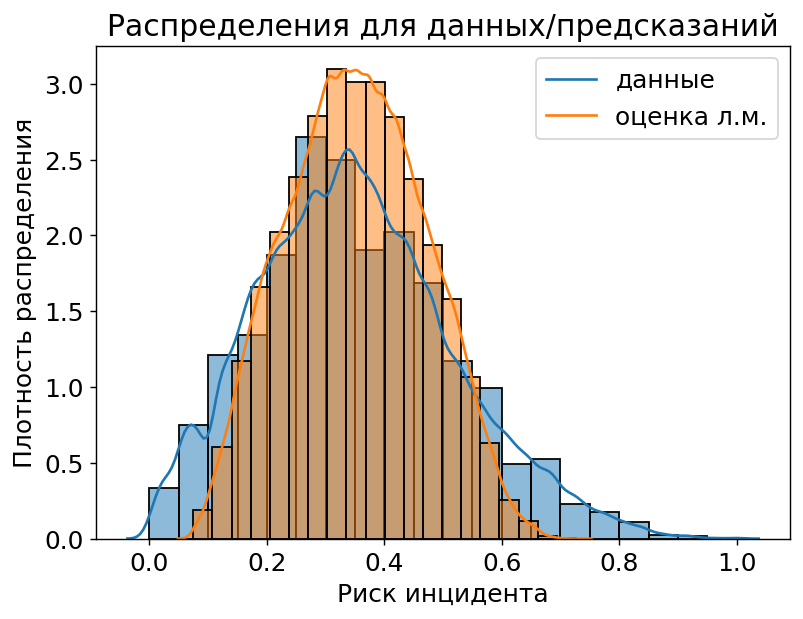

In [10]:
sns.histplot(data=df_train, x='accident_risk', 
             stat='density', bins='sturges', alpha=0.5)
sns.kdeplot(data=df_train, x='accident_risk', label='данные')
sns.histplot(x=preds, stat='density', 
             bins='sturges', alpha=0.5)
sns.kdeplot(x=preds, label='оценка л.м.')
plt.title('Распределения для данных/предсказаний')
plt.ylabel('Плотность распределения')
plt.xlabel('Риск инцидента')
plt.legend()
plt.show()

Для улучшения качества аппроксимации можно рассмотреть использование более сложных моделей, таких как полиномиальная регрессия или нелинейные модели, которые лучше учитывают особенности распределения данных.

Также стоит проверить, достаточно ли данных для обучения модели, особенно в крайних областях, где наблюдается наибольшее расхождение.

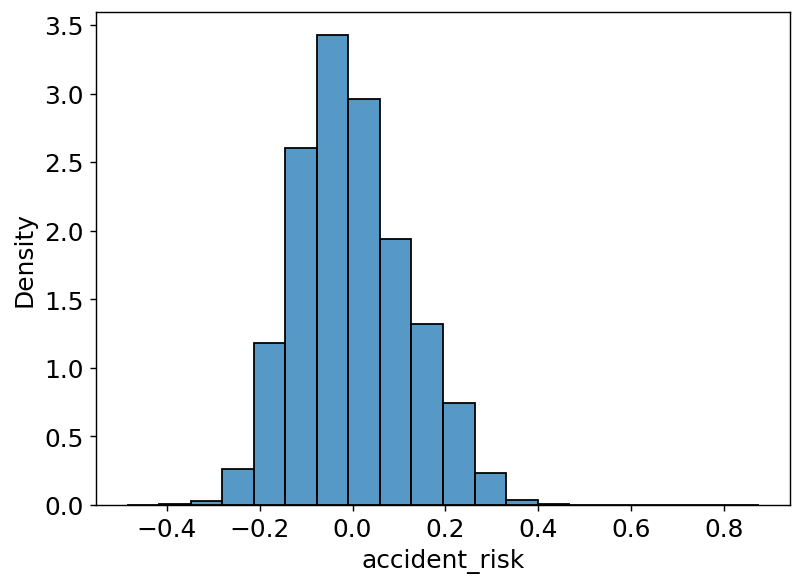

NormaltestResult(statistic=8849.001088234252, pvalue=0.0)
KstestResult(statistic=0.039256506062654184, pvalue=0.0, statistic_location=-0.0696607984561281, statistic_sign=1)


In [11]:
from scipy.stats import kstest, normaltest

errors = df_train['accident_risk'] - preds
sns.histplot(x = errors, 
             stat='density', 
             bins='sturges')
plt.show()

print(normaltest(errors))
print(kstest((errors - np.mean(errors)) / np.std(errors), 'norm'))

Оба теста однозначно указывают на то, что анализируемые данные не соответствуют нормальному распределению. Это подтверждается крайне низкими p-значениями и значительными статистическими показателями.

In [12]:
X_val = df_val[cols_num].drop(columns='accident_risk')
y_val = df_val['accident_risk']

# Фит_предикт тренировки
base_reg_model.fit(X, y)
preds_val = base_reg_model.predict(X_val)

print(f"Оценка R^2 метрики: {r2_score(y_val, preds_val)}")
print(f"Оценка MAE метрики: {mean_absolute_error(y_val, preds_val)}")

Оценка R^2 метрики: 0.4945440697711434
Оценка MAE метрики: 0.09536892668774972


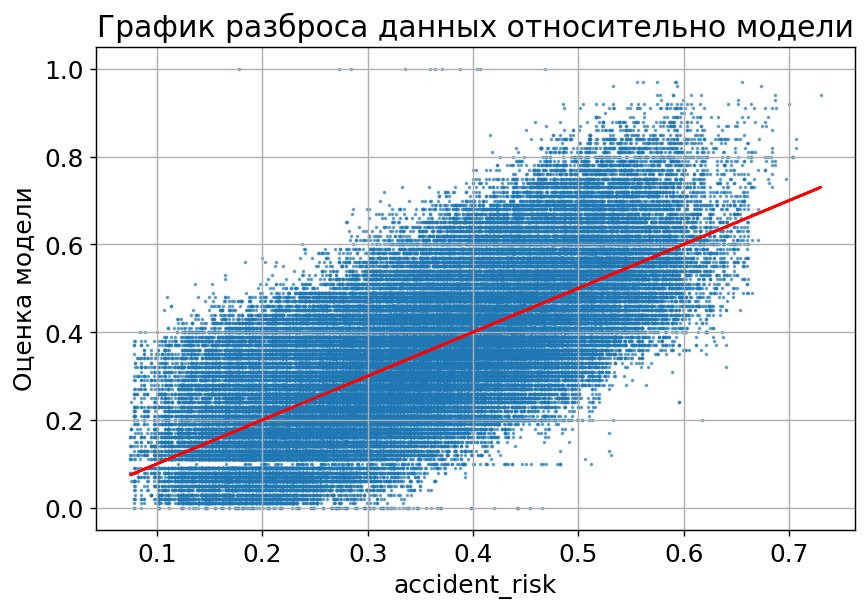

In [13]:
plt.scatter(preds_val, y_val, s=1, alpha=0.6)
plt.plot(preds_val, preds_val, c='red')
plt.title("График разброса данных относительно модели")
plt.xlabel("accident_risk")
plt.ylabel("Оценка модели")
plt.grid()
plt.tight_layout()
plt.show()

# Базовая классификация

In [14]:
# from sklearn.linear_model import LogisticRegression
# from sklearn.metrics import r2_score, mean_absolute_error
# from sklearn.model_selection import KFold

# base_logreg_model = LogisticRegression()

# X = df_train[cols_num].drop(columns='accident_risk')
# y = df_train['accident_risk']
# y_cat = (y > 0.3).replace({True: 1, False: 0})

# kf = KFold(n_splits=5)
# kf.get_n_splits(X)

# scores = []
# for i, (train_index, test_index) in enumerate(kf.split(X)):
#     base_logreg_model.fit(X.loc[train_index], y_cat[train_index])
#     preds = base_logreg_model.predict_proba(X.loc[test_index])
#     scores.append(r2_score(y[test_index], preds[:, 1]))

# print(f"Среднее качество R^2 {np.mean(scores): .4f}")

In [15]:
# # Фит_предикт тренировки
# base_logreg_model.fit(X, y_cat)
# preds_log = base_logreg_model.predict_proba(X)[:, 1]

In [16]:
# sns.histplot(data=df_train, x='accident_risk', 
#              stat='density', bins='sturges', alpha=0.5)
# sns.kdeplot(data=df_train, x='accident_risk', label='данные')
# sns.histplot(x=preds_log, stat='density', 
#              bins='sturges', alpha=0.5)
# sns.kdeplot(x=preds_log, label='оценка лог.м.')
# plt.title('Распределения для данных/предсказаний')
# plt.ylabel('Плотность распределения')
# plt.xlabel('Риск инцидента')
# plt.legend()
# plt.show()

# Просмотр распределений

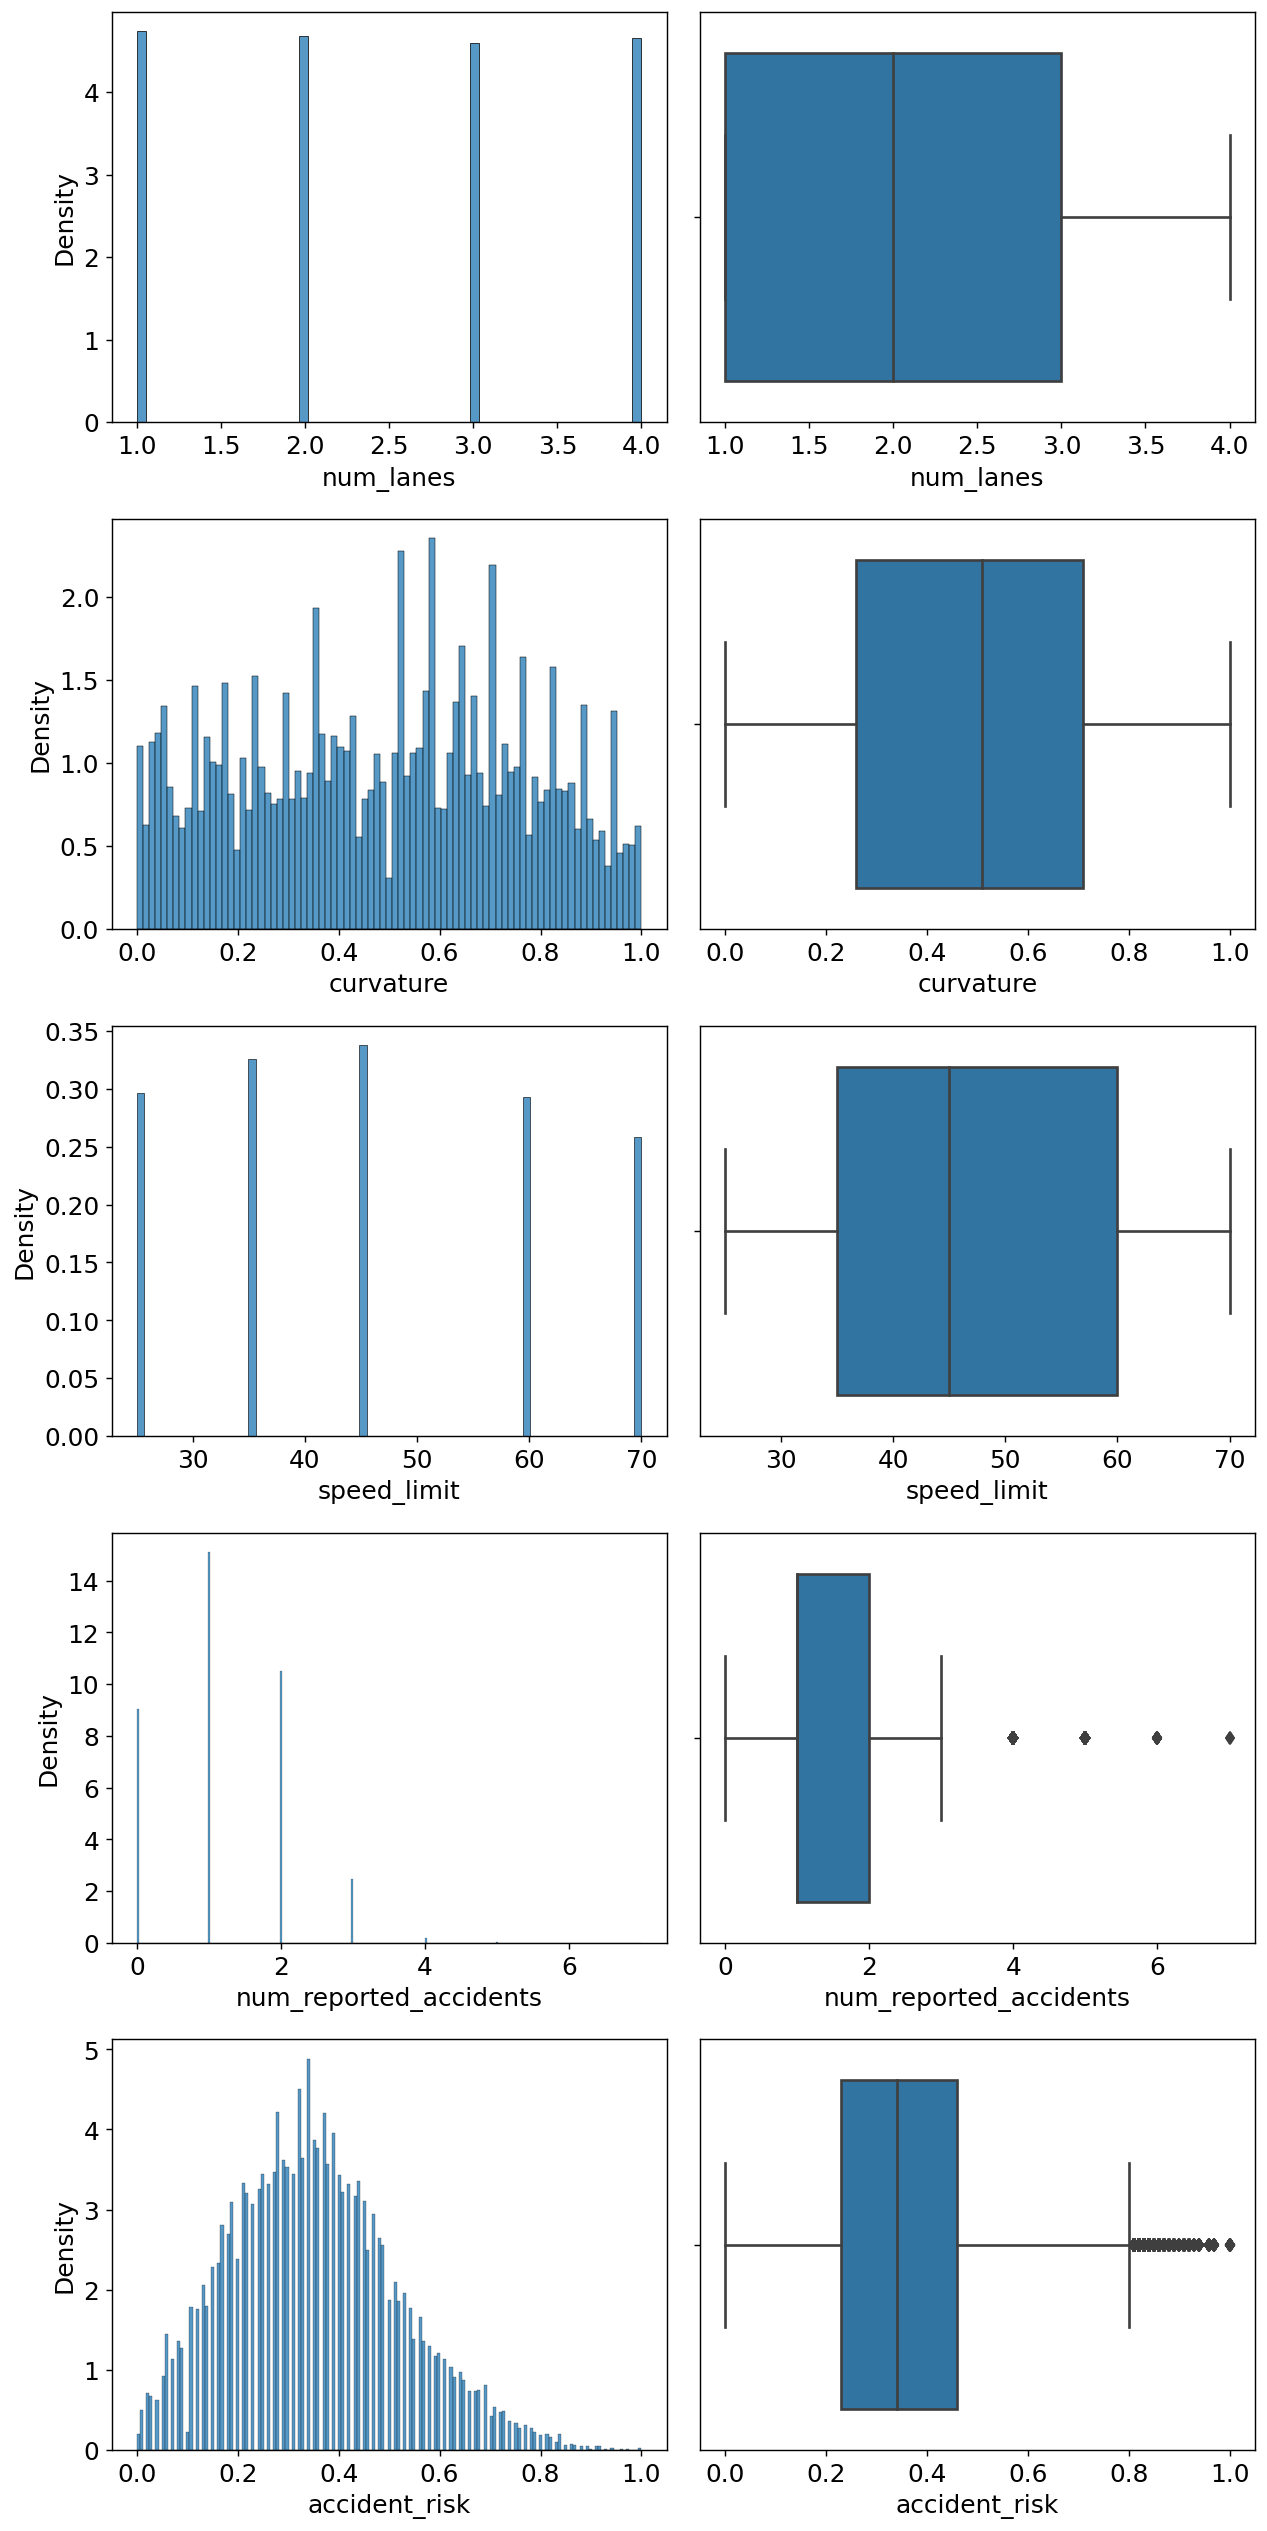

In [17]:
fig, ax = plt.subplots(len(cols_num), 2, 
                       figsize=(10, 4 * len(cols_num)))

for idx, col in enumerate(cols_num):
    sns.histplot(data=df_train, x=col, stat='density', ax=ax[idx, 0])
    sns.boxplot(data=df_train, x=col, ax=ax[idx, 1])
plt.tight_layout()
plt.show()

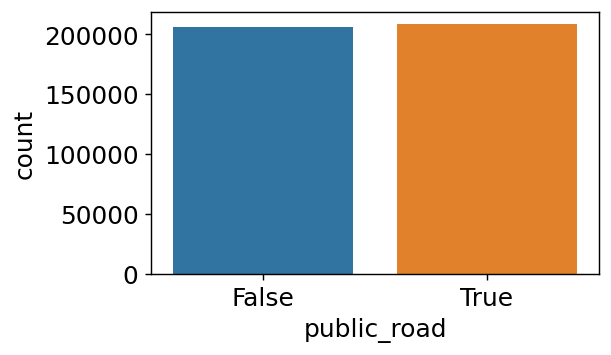

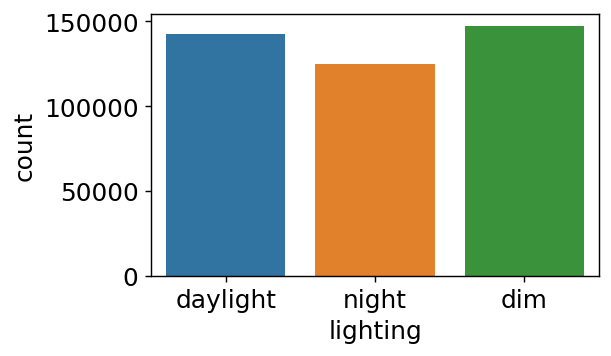

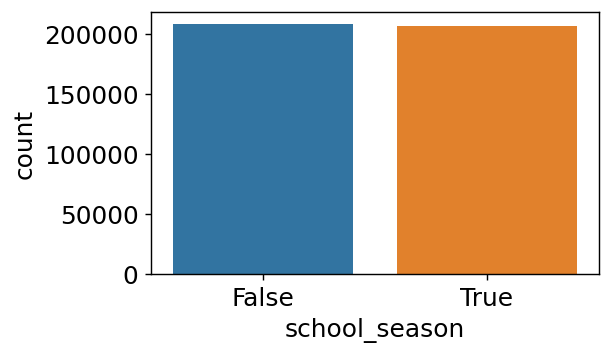

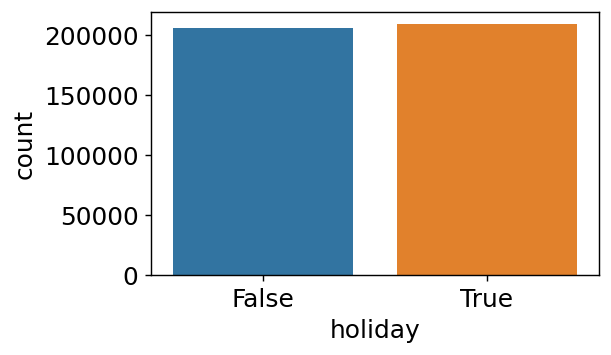

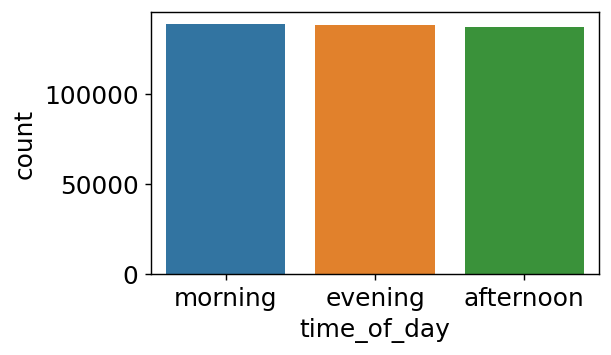

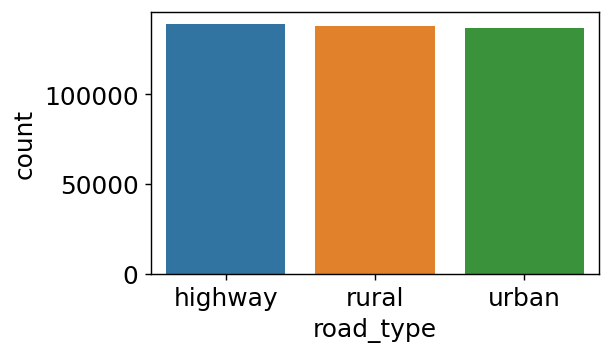

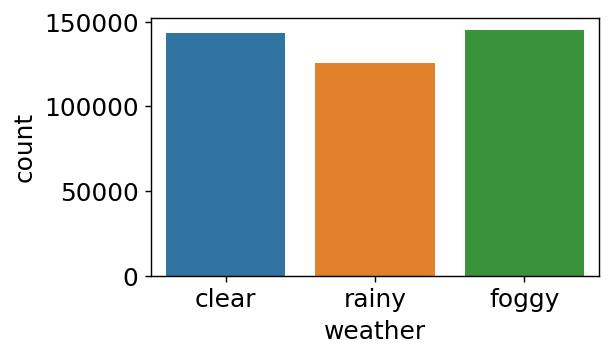

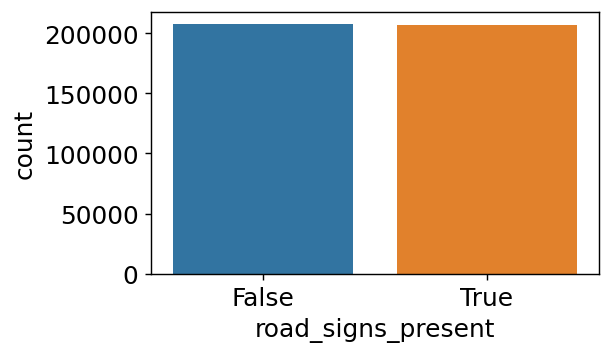

In [18]:
for idx, col in enumerate(cols_cat):
    plt.figure(figsize=(5,3))
    sns.countplot(data=df_train, x=col)
    plt.tight_layout()
    plt.show()

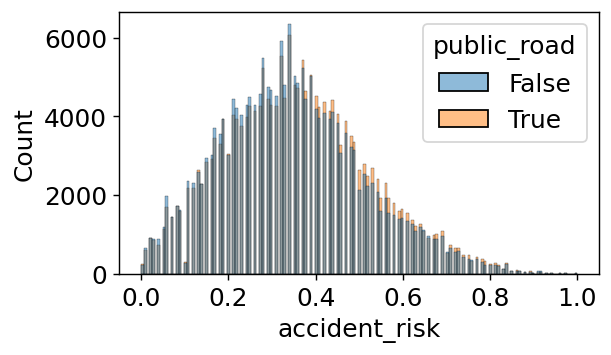

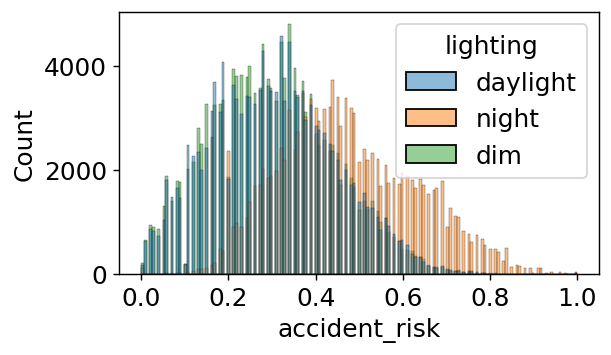

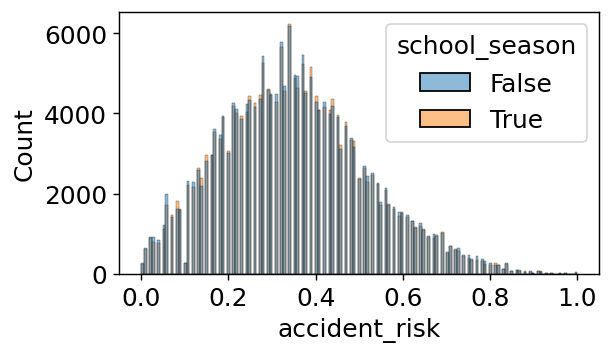

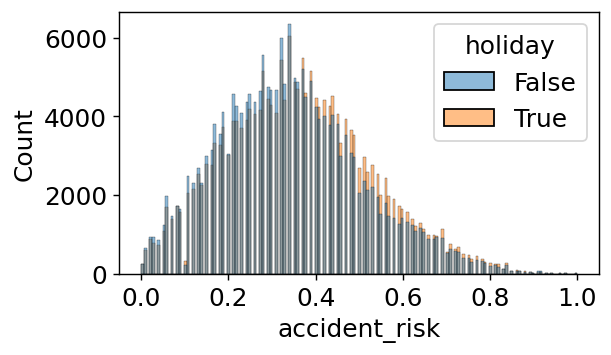

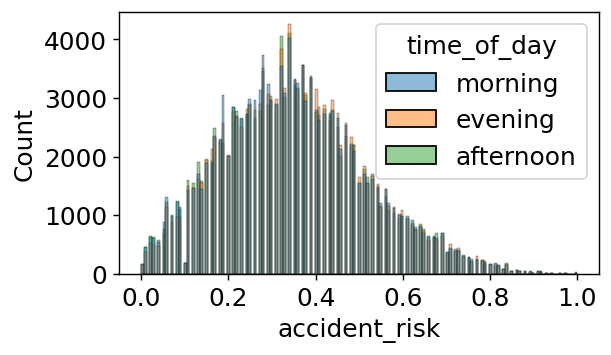

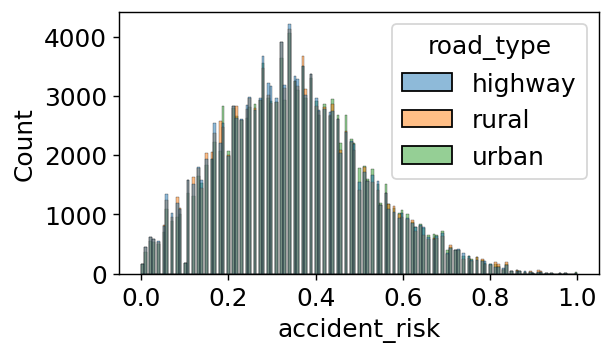

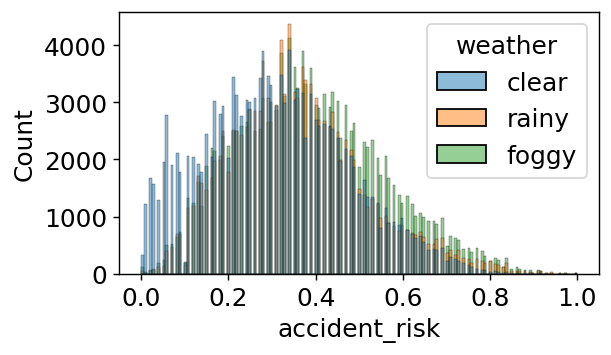

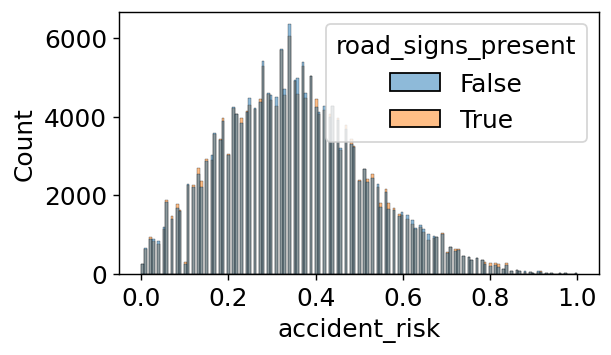

In [19]:
for idx, col in enumerate(cols_cat):
    plt.figure(figsize=(5,3))
    sns.histplot(data=df_train, x='accident_risk', hue=col)
    plt.tight_layout()
    plt.show()

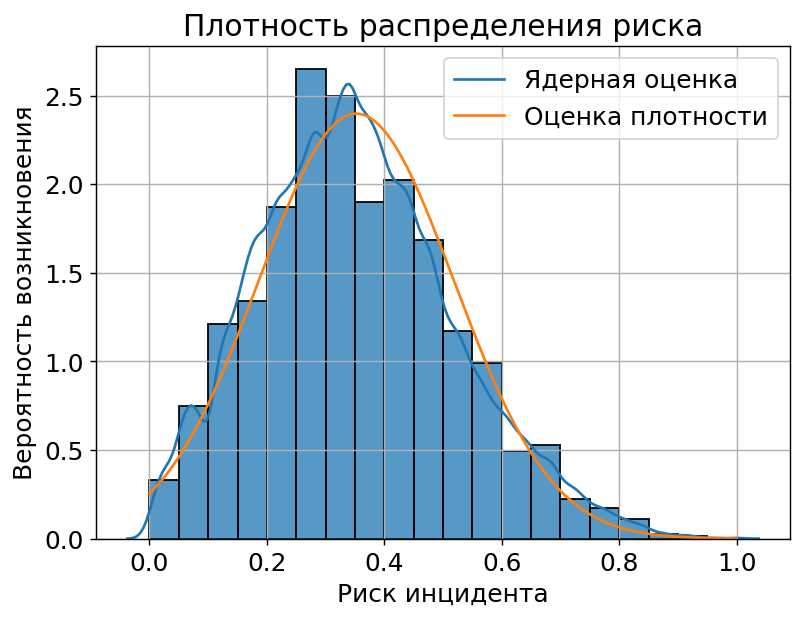

In [20]:
x = np.linspace(0, 1, 1000)
normal = lambda x, m, s: 1/(np.sqrt(2 * np.pi) * s) * np.exp(-(x - m)**2/(2 * s**2))
mean_risk = df_train['accident_risk'].mean()
std_risk = df_train['accident_risk'].std()

sns.histplot(data=df_train, x='accident_risk', stat='density', bins='sturges')
sns.kdeplot(data=df_train, x='accident_risk', label="Ядерная оценка")
sns.lineplot(x=x, 
             y=normal(x, mean_risk, std_risk),
             label="Оценка плотности")
plt.title("Плотность распределения риска")
plt.xlabel("Риск инцидента")
plt.ylabel("Вероятность возникновения")
plt.legend()
plt.grid()
plt.show()

In [21]:
corr = df_train[cols_num].corr('spearman')
corr

,num_lanes,curvature,speed_limit,num_reported_accidents,accident_risk
num_lanes,1.000000,-0.019459,-0.000516,0.015504,-0.007744
curvature,-0.019459,1.000000,0.008992,0.117038,0.546879
speed_limit,-0.000516,0.008992,1.000000,0.021780,0.409160
num_reported_accidents,0.015504,0.117038,0.021780,1.000000,0.152903
accident_risk,-0.007744,0.546879,0.409160,0.152903,1.000000


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


<Axes: >

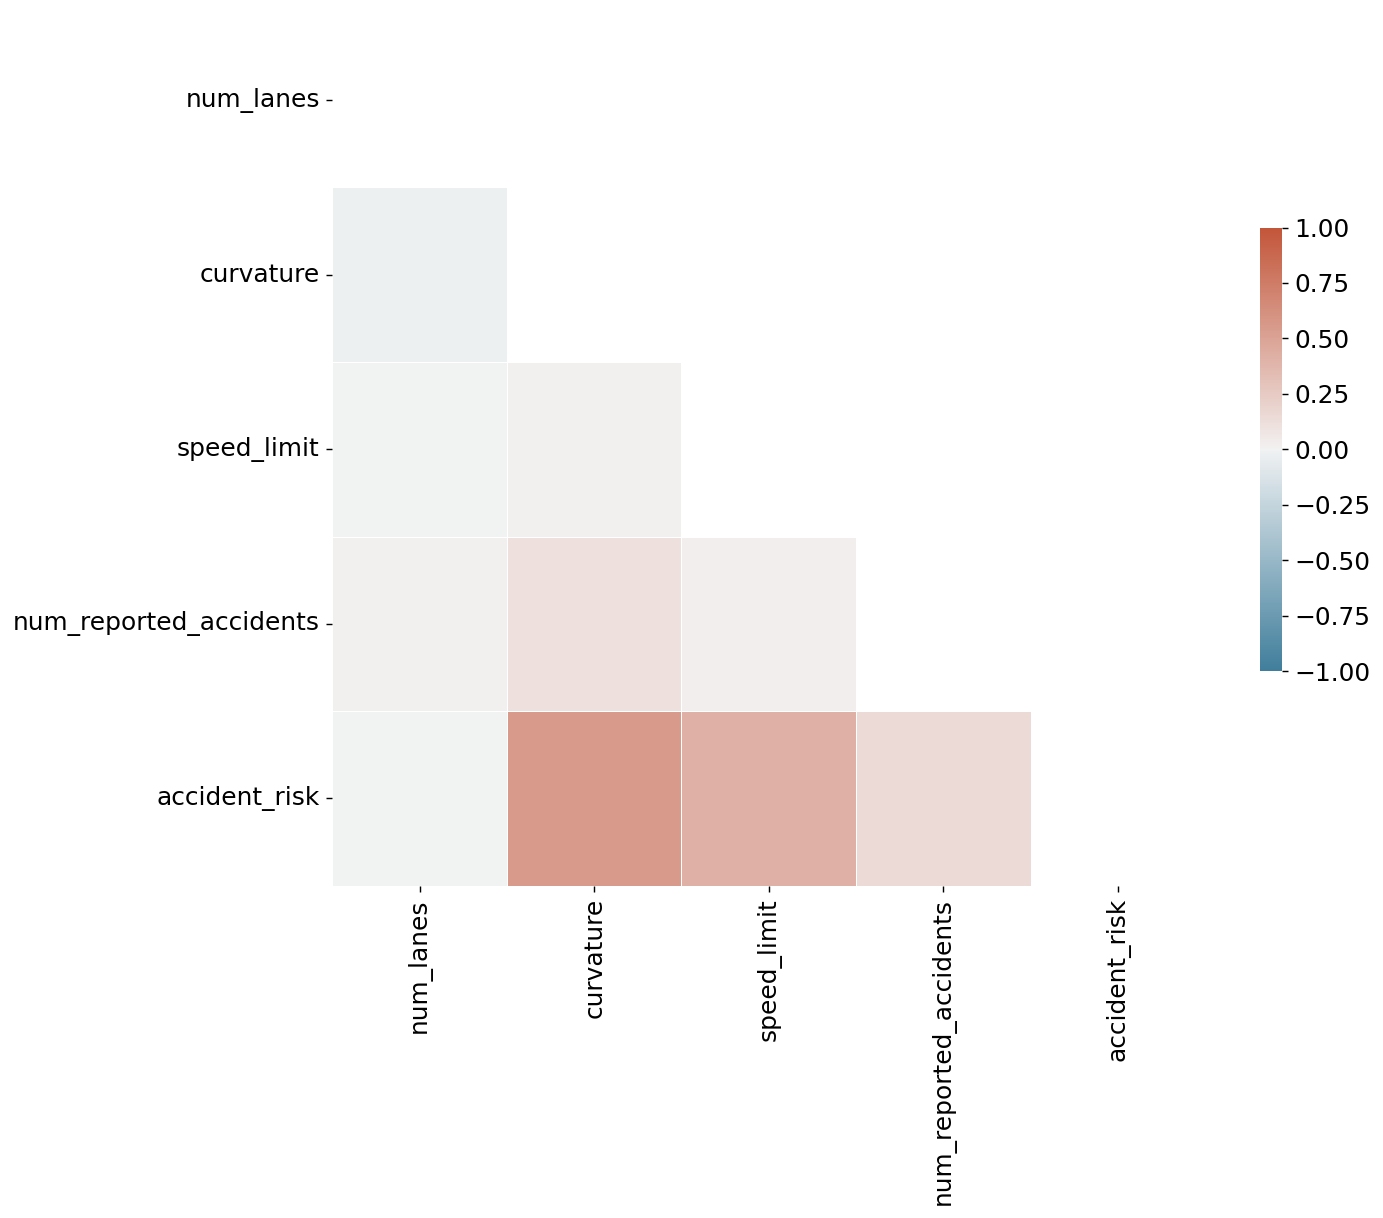

In [22]:
mask = np.triu(np.ones_like(corr, dtype=bool))

# Set up the matplotlib figure
f, ax = plt.subplots(figsize=(11, 9))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr, mask=mask, cmap=cmap, vmax=1, vmin=-1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .5})

# Подготовка категориальных данных

In [23]:
dummies_train = pd.get_dummies(df_train)

pd.concat(
    [
    df_train["lighting"], 
    dummies_train[dummies_train.columns[pd.Series(dummies_train.columns).str.startswith('light')]]
    ], 
    axis=1)

,lighting,lighting_daylight,lighting_dim,lighting_night
0,daylight,True,False,False
1,night,False,False,True
2,night,False,False,True
3,dim,False,True,False
4,night,False,False,True
...,...,...,...,...
414198,dim,False,True,False
414199,dim,False,True,False
414200,night,False,False,True
414201,daylight,True,False,False


In [24]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# Создаем экземпляр OneHotEncoder
encoder = OneHotEncoder(sparse=False,
                        handle_unknown='ignore',
                        drop='first')

# Применяем кодирование к категориальным столбцам
encoded_data = encoder.fit_transform(df_train[cols_cat])

# Создаем новый DataFrame с закодированными значениями
encoded_df = pd.DataFrame(encoded_data, 
                          columns=encoder.get_feature_names_out(cols_cat))

# Объединяем закодированные данные с исходным DataFrame
result = pd.concat([df_train, encoded_df], axis=1).drop(columns=cols_cat)

print(result)

            id  num_lanes  curvature  speed_limit  num_reported_accidents  \
0       173026          1       0.31           45                       1   
1       404541          4       0.33           45                       0   
2       402436          4       0.83           45                       2   
3        94876          4       0.57           35                       1   
4        43875          3       0.75           60                       1   
...        ...        ...        ...          ...                     ...   
414198  112876          2       0.04           35                       1   
414199  347716          3       0.73           25                       3   
414200  301827          1       0.05           35                       1   
414201  457589          3       0.68           25                       0   
414202  113955          1       0.23           70                       0   

        accident_risk  public_road_True  lighting_dim  lighting_night  \
0 

In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.model_selection import cross_validate

class LinRegClip(LinearRegression):
    def predict(self, X):
        return np.clip(LinearRegression.predict(self, X), 0, 1)

reg_model = LinRegClip()

X = result.drop(columns=['id', 'accident_risk'])
y = result['accident_risk']

validator = cross_validate(reg_model, 
                           X, y, 
                           scoring=['r2', 
                                    'neg_root_mean_squared_error'], 
                           cv=5)

print(f"Среднее время обучения {validator.get('fit_time').mean(): .4f} c.")
print(f"Среднее время инференса {validator.get('score_time').mean(): .4f} c.")
print(f"Среднее качество R^2 {validator.get('test_r2').mean(): .4f}")
print(f"Среднее качество NRMSE {validator.get('test_neg_root_mean_squared_error').mean(): .4f}")

Среднее время обучения  0.3797 c.
Среднее время инференса  0.0099 c.
Среднее качество R^2  0.8049
Среднее качество NRMSE -0.0735


In [26]:
# Фит_предикт тренировки
reg_model.fit(X, y)
preds = reg_model.predict(X)

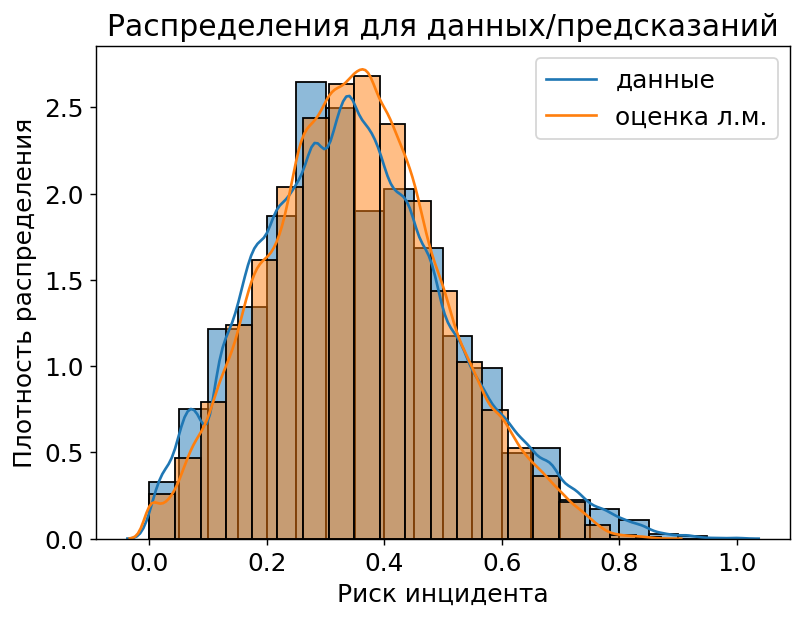

In [27]:
sns.histplot(data=df_train, x='accident_risk', 
             stat='density', bins='sturges', alpha=0.5)
sns.kdeplot(data=df_train, x='accident_risk', label='данные')
sns.histplot(x=preds, stat='density', 
             bins='sturges', alpha=0.5)
sns.kdeplot(x=preds, label='оценка л.м.')
plt.title('Распределения для данных/предсказаний')
plt.ylabel('Плотность распределения')
plt.xlabel('Риск инцидента')
plt.legend()
plt.show()

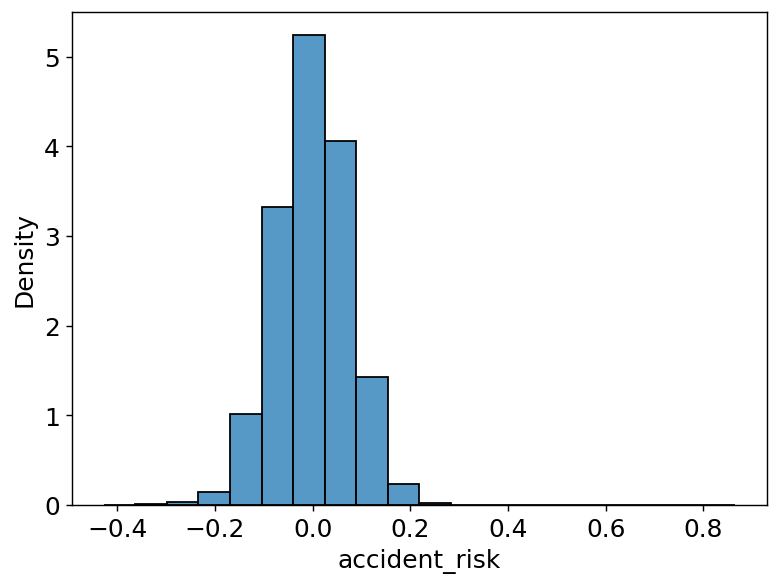

Тест на нормальность:
NormaltestResult(statistic=6787.605741381278, pvalue=0.0)

Тест Колмогорова-Смирнова:
KstestResult(statistic=0.0045695635503800736, pvalue=6.127816890978861e-08, statistic_location=-0.08646993477829754, statistic_sign=-1)


In [28]:
from scipy.stats import kstest, normaltest

errors = df_train['accident_risk'] - preds
sns.histplot(x = errors, 
             stat='density', 
             bins='sturges')
plt.show()

# Статистические тесты
print("Тест на нормальность:")
print(normaltest(errors))

print("\nТест Колмогорова-Смирнова:")
print(kstest((errors - np.mean(errors)) / np.std(errors), 'norm'))

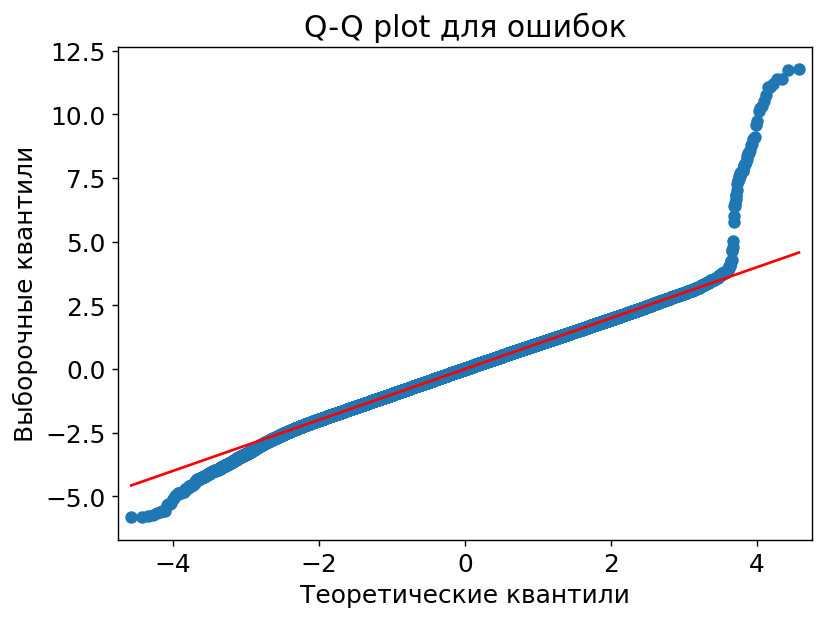

In [29]:
from statsmodels.graphics.gofplots import qqplot

# Q-Q plot с использованием statsmodels
qqplot((errors-np.mean(errors))/np.std(errors), line='s', fit=True, 
       loc=np.mean(errors), scale=np.std(errors))
plt.title('Q-Q plot для ошибок')
plt.xlabel('Теоретические квантили')
plt.ylabel('Выборочные квантили')
plt.show()

In [30]:
# Применяем кодирование к категориальным столбцам
encoded_val = encoder.transform(df_val[cols_cat])

# Создаем новый DataFrame с закодированными значениями
encoded_df_val = pd.DataFrame(encoded_val, columns=encoder.get_feature_names_out(cols_cat))

# Объединяем закодированные данные с исходным DataFrame
result_val = pd.concat([df_val, encoded_df_val], axis=1).drop(columns=cols_cat)

print(result_val)

            id  num_lanes  curvature  speed_limit  num_reported_accidents  \
0       134897          1       0.47           25                       2   
1       369421          3       0.49           45                       0   
2        20868          3       0.62           35                       2   
3       315490          1       0.86           25                       2   
4       278464          1       0.38           35                       1   
...        ...        ...        ...          ...                     ...   
103546   86906          4       0.86           45                       3   
103547  141708          1       0.77           25                       0   
103548  443580          3       0.96           25                       2   
103549  192373          4       0.17           45                       0   
103550  127084          1       0.06           45                       2   

        accident_risk  public_road_True  lighting_dim  lighting_night  \
0 

In [31]:
X_val = result_val.drop(columns=['id', 'accident_risk'])
y_val = result_val['accident_risk']

# Фит_предикт тренировки
reg_model.fit(X, y)
preds_val = reg_model.predict(X_val)

print(f"Оценка R^2 метрики: {r2_score(y_val, preds_val)}")
print(f"Оценка MAE метрики: {mean_absolute_error(y_val, preds_val)}")

Оценка R^2 метрики: 0.8062236638921216
Оценка MAE метрики: 0.05823817554474982


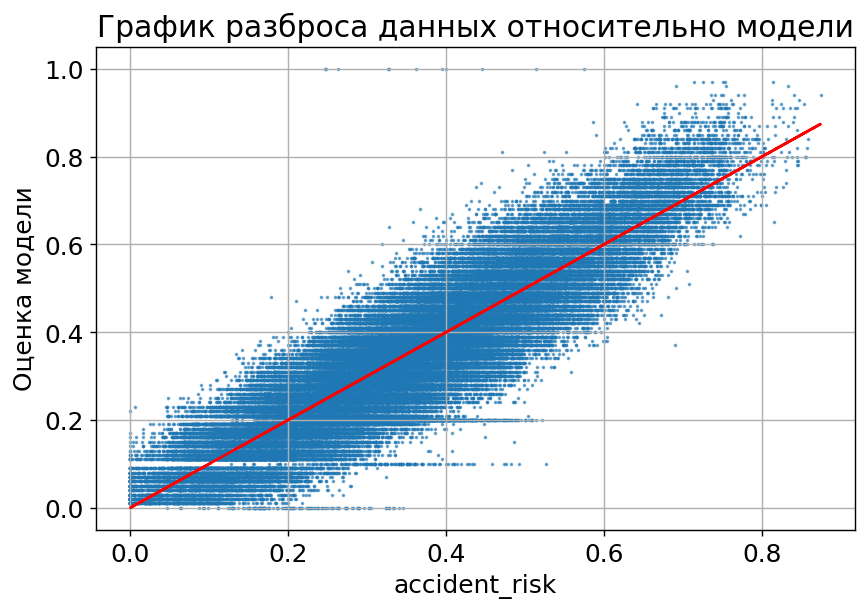

In [32]:
plt.scatter(preds_val, y_val, s=1, alpha=0.6)
plt.plot(preds_val, preds_val, c='red')
plt.title("График разброса данных относительно модели")
plt.xlabel("accident_risk")
plt.ylabel("Оценка модели")
plt.grid()
plt.tight_layout()
plt.show()

In [33]:
coeffs_table = dict(zip(reg_model.feature_names_in_, 
                        reg_model.coef_))
coeffs_table['intercept'] = reg_model.intercept_
coeffs_table

{'num_lanes': 0.0006061283191653257,
 'curvature': 0.3244943998585003,
 'speed_limit': 0.005095792370848881,
 'num_reported_accidents': 0.01571752565513601,
 'public_road_True': -0.0005060825353175105,
 'lighting_dim': -0.00012602741002624464,
 'lighting_night': 0.18728198628053966,
 'school_season_True': 0.00030946307404019005,
 'holiday_True': -0.0004342992999194911,
 'time_of_day_evening': 0.0007587607853438826,
 'time_of_day_morning': -0.0009970670088581806,
 'road_type_rural': -0.0006758845666065133,
 'road_type_urban': -0.00012073358211297288,
 'weather_foggy': 0.09176830675702377,
 'weather_rainy': 0.09293047443260052,
 'road_signs_present_True': -0.0011559600850264938,
 'intercept': -0.17687206666028998}

In [34]:
# Создадим экземпляр данных для того, чтобы проверить работу модели
one_row = dict(zip(
    reg_model.feature_names_in_, 
    [
     [1],                 # 
     [0.2], 
     [25], 
     [0], 
     [False], 
     [False], 
     [False], 
     [False], 
     [False], 
     [False], 
     [False], 
     [False], 
     [False], 
     [False], 
     [False], 
     [False]
    ]   
))
one_row

{'num_lanes': [1],
 'curvature': [0.2],
 'speed_limit': [25],
 'num_reported_accidents': [0],
 'public_road_True': [False],
 'lighting_dim': [False],
 'lighting_night': [False],
 'school_season_True': [False],
 'holiday_True': [False],
 'time_of_day_evening': [False],
 'time_of_day_morning': [False],
 'road_type_rural': [False],
 'road_type_urban': [False],
 'weather_foggy': [False],
 'weather_rainy': [False],
 'road_signs_present_True': [False]}

In [35]:
reg_model.predict(pd.DataFrame(one_row))

array([0.01602775])

# Модель посильнее

In [36]:
from catboost import CatBoostRegressor

model_cb = CatBoostRegressor(iterations=200,
                             depth=3,
                             learning_rate=1,
                             l2_leaf_reg=1.2,
                             loss_function='RMSE',
                             silent=False)

model_cb.fit(X, y)
preds_cb = model_cb.predict(X_val)

0:	learn: 0.0865291	total: 88.6ms	remaining: 17.6s
1:	learn: 0.0702681	total: 110ms	remaining: 10.9s
2:	learn: 0.0617353	total: 130ms	remaining: 8.55s
3:	learn: 0.0598600	total: 151ms	remaining: 7.42s
4:	learn: 0.0590124	total: 171ms	remaining: 6.65s
5:	learn: 0.0587284	total: 190ms	remaining: 6.13s
6:	learn: 0.0581666	total: 210ms	remaining: 5.78s
7:	learn: 0.0577466	total: 232ms	remaining: 5.56s
8:	learn: 0.0576170	total: 251ms	remaining: 5.32s
9:	learn: 0.0574796	total: 271ms	remaining: 5.15s
10:	learn: 0.0574280	total: 292ms	remaining: 5.02s
11:	learn: 0.0573668	total: 312ms	remaining: 4.89s
12:	learn: 0.0573489	total: 332ms	remaining: 4.78s
13:	learn: 0.0573147	total: 351ms	remaining: 4.66s
14:	learn: 0.0572772	total: 369ms	remaining: 4.55s
15:	learn: 0.0572271	total: 388ms	remaining: 4.46s
16:	learn: 0.0571991	total: 407ms	remaining: 4.38s
17:	learn: 0.0571539	total: 426ms	remaining: 4.31s
18:	learn: 0.0570985	total: 445ms	remaining: 4.24s
19:	learn: 0.0570691	total: 466ms	remain

In [37]:
print("RMSE", model_cb.best_score_)
print("R^2:", model_cb.score(X_val, y_val))
print("MAE:", mean_absolute_error(y_val, preds_cb))

RMSE {'learn': {'RMSE': 0.056241687153759885}}
R^2: 0.8857847566921371
MAE: 0.04381164370028541


In [38]:
dict(zip(model_cb.feature_names_, model_cb.feature_importances_))

{'num_lanes': 0.01002856313515127,
 'curvature': 33.79162516020994,
 'speed_limit': 27.588037724620282,
 'num_reported_accidents': 2.9112658156731785,
 'public_road_True': 0.014596971052269179,
 'lighting_dim': 0.0066151957287823,
 'lighting_night': 25.440270929259967,
 'school_season_True': 0.002941480284635003,
 'holiday_True': 0.017932932492488226,
 'time_of_day_evening': 0.0036706383298807585,
 'time_of_day_morning': 0.00212780182800692,
 'road_type_rural': 0.00109280917554525,
 'road_type_urban': 0.0016806633104489053,
 'weather_foggy': 5.3534609242842786,
 'weather_rainy': 4.85067519474579,
 'road_signs_present_True': 0.0039771958693484875}

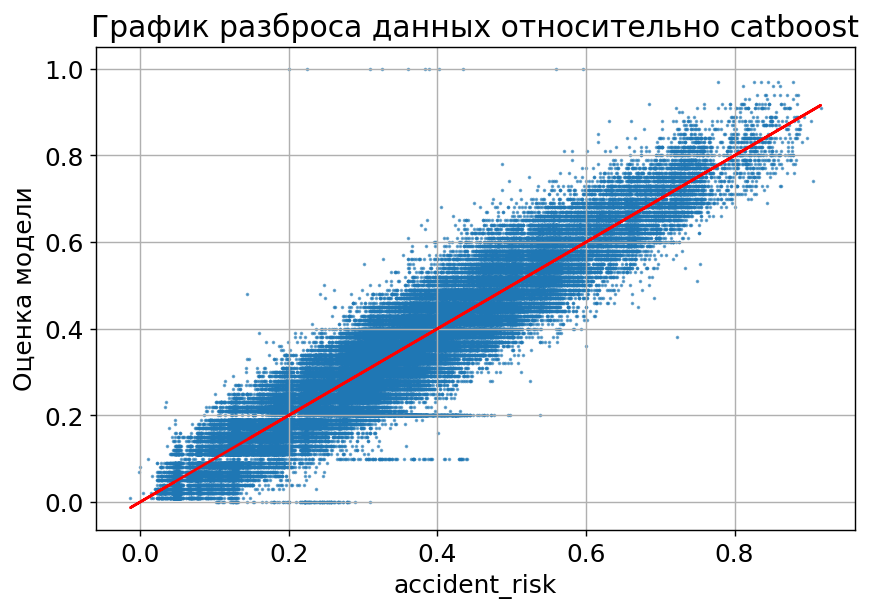

In [39]:
plt.scatter(preds_cb, y_val, s=1, alpha=0.6)
plt.plot(preds_cb, preds_cb, c='red')
plt.title("График разброса данных относительно catboost")
plt.xlabel("accident_risk")
plt.ylabel("Оценка модели")
plt.grid()
plt.tight_layout()
plt.show()

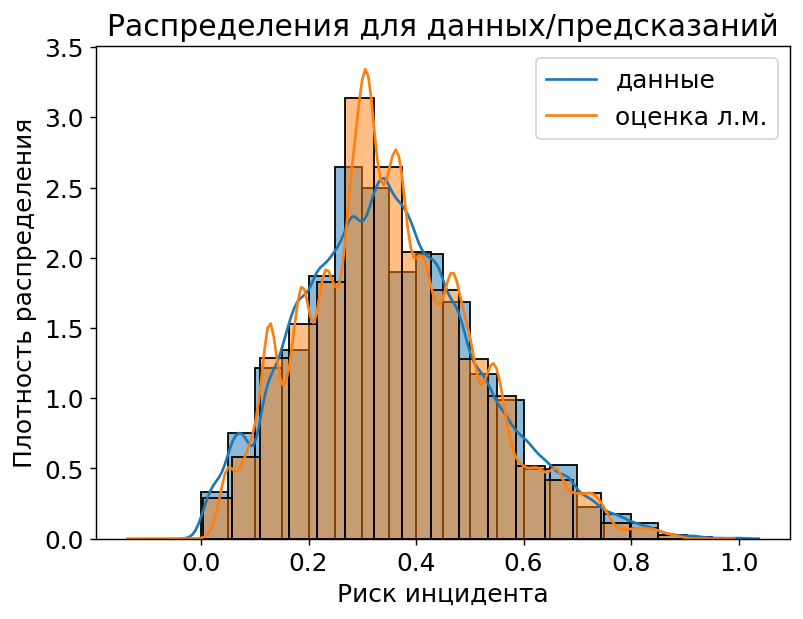

In [40]:
# Фит_предикт тренировки
preds_cb_train = model_cb.predict(X)


sns.histplot(data=df_train, x='accident_risk', 
             stat='density', bins='sturges', alpha=0.5)
sns.kdeplot(data=df_train, x='accident_risk', label='данные')
sns.histplot(x=preds_cb_train, stat='density', 
             bins='sturges', alpha=0.5)
sns.kdeplot(x=preds_cb_train, label='оценка л.м.')
plt.title('Распределения для данных/предсказаний')
plt.ylabel('Плотность распределения')
plt.xlabel('Риск инцидента')
plt.legend()
plt.show()

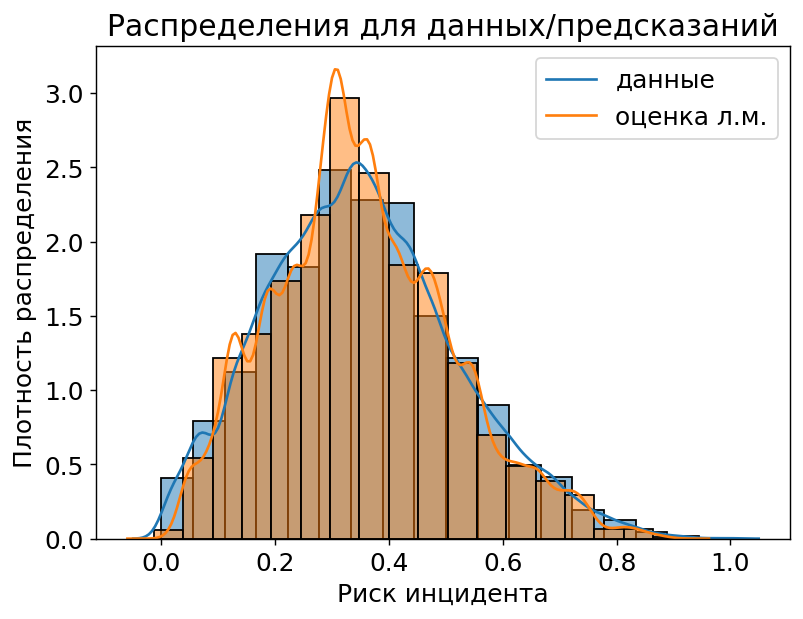

In [41]:
sns.histplot(data=df_val, x='accident_risk', 
             stat='density', bins='sturges', alpha=0.5)
sns.kdeplot(data=df_val, x='accident_risk', label='данные')
sns.histplot(x=preds_cb, stat='density', 
             bins='sturges', alpha=0.5)
sns.kdeplot(x=preds_cb, label='оценка л.м.')
plt.title('Распределения для данных/предсказаний')
plt.ylabel('Плотность распределения')
plt.xlabel('Риск инцидента')
plt.legend()
plt.show()

In [42]:
# Создадим экземпляр данных для того, чтобы проверить работу модели
one_row = dict(zip(
    model_cb.feature_names_, 
    [
     [1],                 # 
     [0.2], 
     [25], 
     [0], 
     [False], 
     [False], 
     [False], 
     [False], 
     [False], 
     [False], 
     [False], 
     [False], 
     [False], 
     [False], 
     [False], 
     [False]
    ]   
))
one_row

{'num_lanes': [1],
 'curvature': [0.2],
 'speed_limit': [25],
 'num_reported_accidents': [0],
 'public_road_True': [False],
 'lighting_dim': [False],
 'lighting_night': [False],
 'school_season_True': [False],
 'holiday_True': [False],
 'time_of_day_evening': [False],
 'time_of_day_morning': [False],
 'road_type_rural': [False],
 'road_type_urban': [False],
 'weather_foggy': [False],
 'weather_rainy': [False],
 'road_signs_present_True': [False]}

In [43]:
model_cb.predict(pd.DataFrame(one_row))

array([0.08074341])

# Предсказание с помощью моделей для теста

In [44]:
from catboost import CatBoostRegressor

encoded_full = encoder.transform(df[cols_cat])
encoded_df_full = pd.DataFrame(encoded_full, 
                               columns=encoder.get_feature_names_out(cols_cat))
result_full = pd.concat([df, encoded_df_full], axis=1).drop(columns=cols_cat)

X_full = result_full.drop(columns=['id', 'accident_risk'])
y_full = result_full['accident_risk']

reg_model = LinRegClip()

model_cb = CatBoostRegressor(iterations=1000,
                             depth=4,
                             learning_rate=1,
                             l2_leaf_reg=0,
                             loss_function='RMSE',
                             silent=True)

reg_model.fit(X_full, y_full)
model_cb.fit(X_full, y_full)

In [45]:
test_path = "/kaggle/input/playground-series-s5e10/test.csv"
df_test = pd.read_csv(test_path)
df_test.isna().sum()

id                        0
road_type                 0
num_lanes                 0
curvature                 0
speed_limit               0
lighting                  0
weather                   0
road_signs_present        0
public_road               0
time_of_day               0
holiday                   0
school_season             0
num_reported_accidents    0
dtype: int64

In [46]:
encoded_test = encoder.transform(df_test[cols_cat])
encoded_df_test = pd.DataFrame(encoded_test, 
                               columns=encoder.get_feature_names_out(cols_cat))
result_test = pd.concat([df_test, encoded_df_test], axis=1).drop(columns=cols_cat)

X_test = result_test.drop(columns=['id'])

preds_cb = model_cb.predict(X_test)
preds_lr = reg_model.predict(X_test)

In [47]:
submission_cb = pd.DataFrame({'id': df_test.id, 'accident_risk': preds_cb})
submission_cb.to_csv("submission_cb.csv", index=False)

In [48]:
submission_lr = pd.DataFrame({'id': df_test.id, 'accident_risk': preds_lr})
submission_lr.to_csv("submission_lr.csv", index=False)

In [49]:
submission_ = pd.DataFrame({'id': df_test.id, 'accident_risk': preds_lr*0.15 + preds_cb*0.85})
submission_.to_csv("submission.csv", index=False)

# Модель на PyTorch

In [50]:
# ====== Импорт ======
import os, math, warnings, json, pickle
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

import matplotlib.pyplot as plt
from IPython.display import clear_output


# Константы
RANDOM_SEED = 42
VAL_SIZE    = 0.1
BATCH_SIZE  = 512
EPOCHS      = 100
LR          = 1e-3
WEIGHT_DECAY= 0.0
PATIENCE    = 10      # ранняя остановка
MIN_DELTA   = 1e-6
PLOT_EVERY  = 2       # график каждые N эпох

cols_num = list(cols_num)
if 'accident_risk' in cols_num:
    cols_num.remove('accident_risk')

# ====== Утилиты ======
def set_seed(seed=RANDOM_SEED):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [51]:
class NumpyDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = torch.from_numpy(X.astype(np.float32))
        self.y = None if y is None else torch.from_numpy(y.astype(np.float32)).reshape(-1, 1)
        
    def __len__(self): 
        return self.X.shape[0]
    
    def __getitem__(self, i):
        if self.y is None: 
            return self.X[i]
        return self.X[i], self.y[i]

In [52]:
class EarlyStopping:
    def __init__(self, patience=PATIENCE, min_delta=MIN_DELTA):
        self.patience = patience 
        self.min_delta = min_delta
        self.best_loss = math.inf 
        self.counter = 0
        self.best_state = None 
        self.best_epoch = -1
    
    def step(self, val_loss, model, epoch):
        improved = (self.best_loss - val_loss) > self.min_delta
        if improved:
            self.best_loss = val_loss
            self.counter = 0
            self.best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            self.best_epoch = epoch
            return False
        self.counter += 1
        return self.counter >= self.patience

In [53]:
class MLP(nn.Module):
    # простая полносвязная сеть
    def __init__(self, in_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )
    def forward(self, x): 
        return self.net(x)

In [54]:
train = df
test  = df_test

X_train_df = train.drop(columns=['accident_risk'])
y_train = train['accident_risk']
X_test_df  = test.copy()

# One-hot категориальные
full_cat = pd.get_dummies(X_train_df[cols_cat], drop_first=False)

# Масштабируем числовые
scaler = StandardScaler()
full_num = pd.DataFrame(
    scaler.fit_transform(X_train_df[cols_num]),
    columns=cols_num, index=X_train_df.index
)

# Финальная матрица признаков
X_train = pd.concat([full_num, full_cat], axis=1)
print(X_train.head())

   num_lanes  curvature  speed_limit  num_reported_accidents  public_road  \
0  -0.438680  -1.572918    -0.703840               -0.209797         True   
1   1.346344   1.839137    -0.703840               -1.325918        False   
2   1.346344   0.518342     1.512963                0.906324         True   
3   1.346344  -1.536229    -0.703840               -0.209797         True   
4  -1.331192   0.334898     0.879591               -0.209797        False   

   school_season  holiday  road_signs_present  lighting_daylight  \
0           True    False               False               True   
1           True     True                True               True   
2          False     True               False              False   
3          False    False                True              False   
4          False     True               False               True   

   lighting_dim  lighting_night  time_of_day_afternoon  time_of_day_evening  \
0         False           False                  

In [55]:
# ====== Train/Val разделение ======
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=VAL_SIZE, random_state=RANDOM_SEED
)
X_tr = np.array(X_tr)
X_val = np.array(X_val)
y_tr = np.array(y_tr)
y_val = np.array(y_val)

train_loader = DataLoader(NumpyDataset(X_tr, y_tr), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(NumpyDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)

In [56]:
# ====== Модель и обучение ======
model = MLP(in_dim=X_tr.shape[1]).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

train_losses, val_losses = [], []
es = EarlyStopping()

Эпоха 36/100 | train: 0.003241 | valid: 0.003237


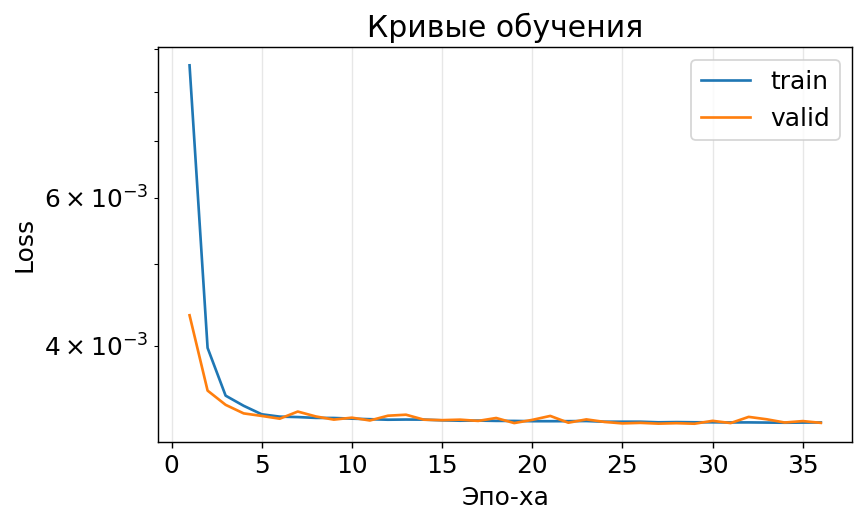

Ранняя остановка на эпохе 37. Лучшая: 28, val_loss=0.003230
Финальная valid loss: 0.003258 (лучшая: 0.003230 на эпохе 28)


In [57]:
for epoch in range(1, EPOCHS+1):
    # --- train ---
    model.train()
    tr_sum = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        pred = model(xb)
        loss = criterion(pred, yb)
        loss.backward()
        optimizer.step()
        tr_sum += loss.item() * xb.size(0)
    tr_loss = tr_sum / len(train_loader.dataset)

    # --- valid ---
    model.eval()
    val_sum = 0.0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb)
            loss = criterion(pred, yb)
            val_sum += loss.item() * xb.size(0)
    v_loss = val_sum / len(val_loader.dataset)

    train_losses.append(tr_loss); val_losses.append(v_loss)

    if epoch == 1 or epoch % PLOT_EVERY == 0:
        clear_output(wait=True)
        print(f"Эпоха {epoch}/{EPOCHS} | train: {tr_loss:.6f} | valid: {v_loss:.6f}")
        plt.figure(figsize=(7,4))
        plt.plot(range(1, len(train_losses)+1), train_losses, label="train")
        plt.plot(range(1, len(val_losses)+1),   val_losses,   label="valid")
        plt.xlabel("Эпо-ха")
        plt.ylabel("Loss")
        plt.yscale('log')
        plt.title("Кривые обучения")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.show()

    if es.step(v_loss, model, epoch):
        print(f"Ранняя остановка на эпохе {epoch}. Лучшая: {es.best_epoch+1}, val_loss={es.best_loss:.6f}")
        model.load_state_dict(es.best_state)
        break

print(f"Финальная valid loss: {val_losses[-1]:.6f} (лучшая: {es.best_loss:.6f} на эпохе {es.best_epoch+1})")

In [58]:
# ====== Простая оценка на валидации ======
model.eval()
with torch.no_grad():
    val_logits = model(torch.from_numpy(X_val.astype(np.float32)).to(device)).cpu().numpy().ravel()


val_preds = val_logits
mae  = metrics.mean_absolute_error(y_val, val_preds)
rmse = metrics.mean_squared_error(y_val, val_preds, squared=False)
r2   = metrics.r2_score(y_val, val_preds)
print(f"Валидация (regression): MAE={mae:.4f} | RMSE={rmse:.4f} | R2={r2:.4f}")

Валидация (regression): MAE=0.0440 | RMSE=0.0568 | R2=0.8829


In [59]:
test_cat = pd.get_dummies(X_test_df[cols_cat], drop_first=False)
test_num = pd.DataFrame(
    scaler.transform(X_test_df[cols_num]),
    columns=cols_num, index=X_test_df.index
)

X_test = np.array(pd.concat([test_num, test_cat], axis=1))

# ====== Предсказания на test ======
with torch.no_grad():
    test_logits = model(torch.from_numpy(X_test.astype(np.float32)).to(device)).cpu().numpy().ravel()

out = pd.DataFrame({"id":df_test.id, "accident_risk": test_logits})
out.to_csv("predictions.csv", index=False)